# 01 — Il dataset e le stime preliminari

Materiale per i capitoli su **acquisizione e preprocessing**. Il dataset è quello prodotto
da `data_collection_robot_angles.py`: 11 sessioni in `data/raw/dati_tesi/`, ciascuna
nominata `<ripetizione>_<velocita_comandata>`, con la matrice `[timestamp, j1, …, j6]` in
radianti campionata a 25 Hz.

Qui si verifica che il campionamento sia utilizzabile, si isolano i singoli movimenti e si
ricava la prima stima di `vmax` e `amax`. Il risultato che conta: **`vmax` cresce
linearmente con la velocità comandata**, mentre `amax` a questo stadio è una sottostima e
serve solo come punto di partenza per il fitting del notebook `03`.

In [1]:
# --- Grafici interattivi (zoom, pan, salvataggio dalla toolbar) ---------------
# Il backend `widget` di ipympl rende zoomabili le figure matplotlib direttamente
# nel notebook, senza cambiare una riga del codice di disegno. Se ipympl non e'
# installato si ricade sul backend statico `inline`, cosi' il notebook resta
# eseguibile ovunque; impostare MPL_STATIC=1 forza il comportamento statico.
import os

from IPython import get_ipython

_ip = get_ipython()
if os.environ.get("MPL_STATIC") or _ip is None:
    _BACKEND = "inline"
else:
    try:
        import ipympl  # noqa: F401
        _BACKEND = "widget"
    except ImportError:
        _BACKEND = "inline"
if _ip is not None:
    _ip.run_line_magic("matplotlib", _BACKEND)

import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Il notebook sta in notebooks/, il pacchetto in ../src
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.preprocessing import (
    PreprocessingConfig,
    analyze_dataset,
    analyze_joint_movement,
    check_sampling_uniformity,
    load_position_data,
    save_results,
    segment_movements,
)

DATA_RAW = ROOT / "data" / "raw" / "dati_tesi"
DATA_PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "results" / "figures"
TABLES = ROOT / "results" / "tables"

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("Radice progetto:", ROOT)
print("Dati grezzi    :", DATA_RAW.resolve())
print(f"backend matplotlib: {_BACKEND}"      + ("  (grafici interattivi)" if _BACKEND == "widget" else "  (statico)"))

/home/lorenzo/introb/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


Radice progetto: /home/lorenzo/introb/thesis_project
Dati grezzi    : /home/lorenzo/introb/thesis_project/data/raw/dati_tesi
backend matplotlib: inline  (statico)


In [2]:
sessione = DATA_RAW / "1_50"
df = load_position_data(sessione / "mycobot280_angle_data.csv")
print(f"sessione {sessione.name}: {len(df)} campioni, {df['timestamp'].iloc[-1]:.1f} s")

sessione 1_50: 2856 campioni, 136.7 s


## 1. Qualità del campionamento

Lo script punta a 25 Hz con un loop temporizzato su `perf_counter`. Il controllo conta
perché `compute_derivatives` assume passo costante: un jitter elevato diventerebbe errore
sulle derivate.

**Il CV enorme del Δt non è jitter.** La sessione contiene 12 movimenti separati da pause
in cui l'acquisizione è sospesa, e quelle pause sono buchi di alcuni secondi. Il jitter
vero va misurato **dentro** i segmenti.

In [3]:
t = df["timestamp"].to_numpy()
report = check_sampling_uniformity(t)
print(f"Sessione intera : {report['n_samples']} campioni, "
      f"dt mediano = {report['dt_median']*1e3:.2f} ms "
      f"(fs = {report['fs_est']:.2f} Hz), CV = {report['cv']*100:.2f}%, "
      f"{report['n_gaps']} buchi temporali")

dt = np.diff(t)
soglia_buco = 5 * np.median(dt)
dt_interno = dt[dt <= soglia_buco]
cv_interno = dt_interno.std() / dt_interno.mean()

print(f"Solo dentro i segmenti: dt medio = {dt_interno.mean()*1e3:.2f} ms "
      f"(fs = {1/dt_interno.mean():.2f} Hz), CV = {cv_interno*100:.2f}%")
print(f"Campioni persi (dt ~ 2 periodi): {int((dt_interno > 1.5*np.median(dt)).sum())}")

Sessione intera : 2856 campioni, dt mediano = 40.00 ms (fs = 25.00 Hz), CV = 338.74%, 11 buchi temporali
Solo dentro i segmenti: dt medio = 40.07 ms (fs = 24.95 Hz), CV = 8.04%
Campioni persi (dt ~ 2 periodi): 12


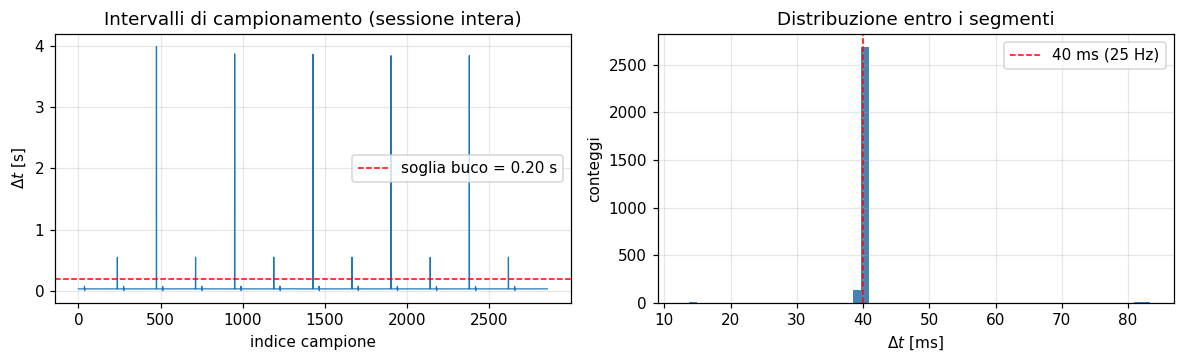

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))

axes[0].plot(dt, lw=0.8)
axes[0].axhline(soglia_buco, color="r", ls="--", lw=1, label=f"soglia buco = {soglia_buco:.2f} s")
axes[0].set(xlabel="indice campione", ylabel=r"$\Delta t$ [s]",
            title="Intervalli di campionamento (sessione intera)")
axes[0].legend()

axes[1].hist(dt_interno * 1e3, bins=60, color="steelblue")
axes[1].axvline(1000 / 25, color="r", ls="--", lw=1, label="40 ms (25 Hz)")
axes[1].set(xlabel=r"$\Delta t$ [ms]", ylabel="conteggi",
            title="Distribuzione entro i segmenti")
axes[1].legend()

fig.tight_layout()
fig.savefig(FIGURES / "01_campionamento.png", dpi=150, bbox_inches="tight")
plt.show()

I picchi isolati a ~80 ms sono singoli campioni persi dal loop. Sono pochi e non alterano
il passo mediano, quindi il segnale resta trattabile come uniformemente campionato a 25 Hz.

## 2. Segmentazione dei movimenti

`segment_movements` usa i buchi temporali per separare i movimenti e identifica il giunto
mosso come quello con escursione maggiore. Attesi **12 segmenti**: 6 giunti × 2 transizioni.

Un segmento però non è tutto movimento: contiene anche la quiete di baseline registrata
prima del comando e l'assestamento dopo l'arrivo, che insieme ne occupano circa due terzi.
Nella figura le bande grigie usano `motion_bounds` per marcare il **solo tratto in moto**,
e ogni pannello mostra i movimenti del proprio giunto.

In [5]:
joint_names = list(df.columns[1:])
positions = df[joint_names].to_numpy()
segmenti = segment_movements(t, positions, joint_names=joint_names)

pd.DataFrame([{
    "seg": s.index,
    "giunto": s.joint_name,
    "n_campioni": s.stop - s.start,
    "durata_s": round(s.duration, 2),
    "q_iniziale_rad": round(float(s.position[0]), 3),
    "q_finale_rad": round(float(s.position[-1]), 3),
    "delta_q_rad": round(s.travel, 3),
} for s in segmenti])
None

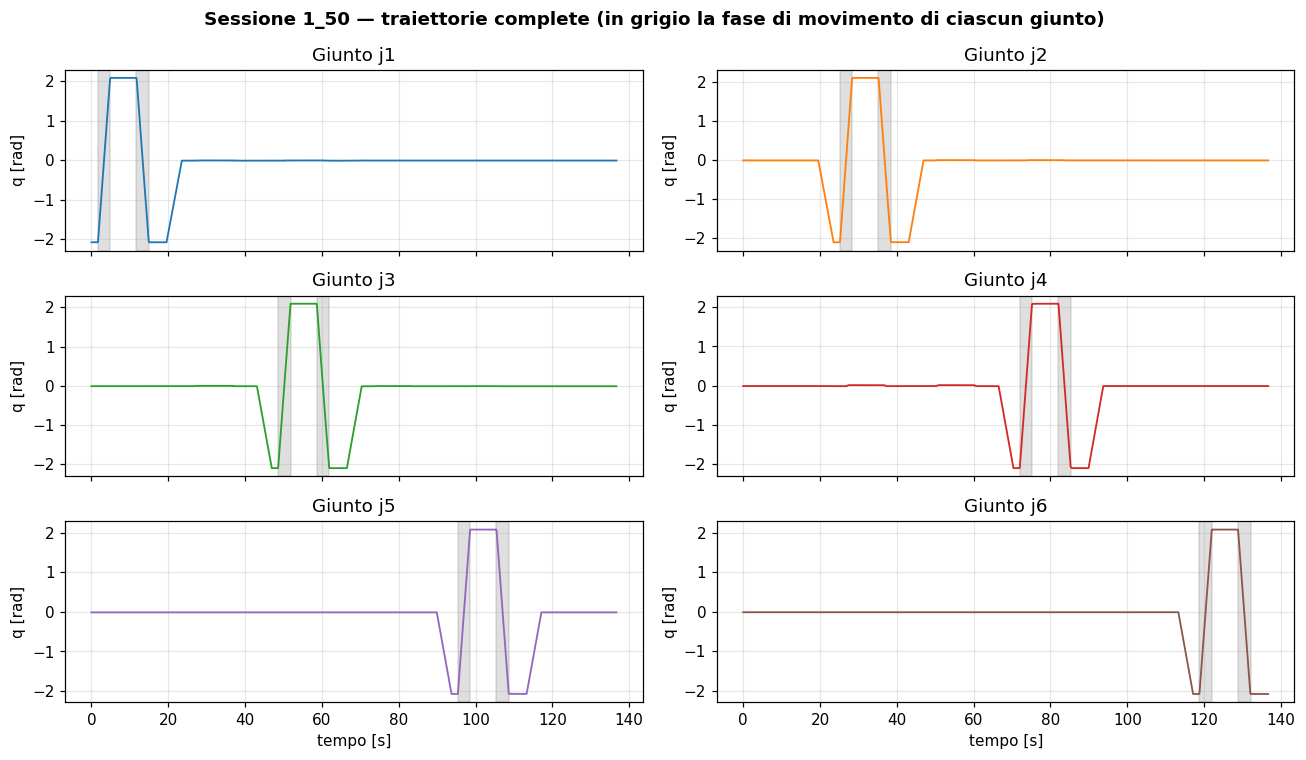

In [6]:
fig, axes = plt.subplots(3, 2, figsize=(12, 7), sharex=True)
colori = plt.cm.tab10(np.linspace(0, 1, 10))

for i, ax in enumerate(axes.flatten()):
    ax.plot(t, positions[:, i], lw=1.2, color=colori[i])
    for s in segmenti:
        if s.joint_index != i:
            continue                       # su ogni pannello solo i movimenti di quel giunto
        a, b = s.motion_bounds             # indici relativi al segmento: vanno riportati su t
        ax.axvspan(t[s.start + a], t[s.start + b - 1], color="grey", alpha=0.25)
    ax.set(title=f"Giunto {joint_names[i]}", ylabel="q [rad]")
axes[-1, 0].set_xlabel("tempo [s]")
axes[-1, 1].set_xlabel("tempo [s]")
fig.suptitle("Sessione 1_50 — traiettorie complete "
             "(in grigio la fase di movimento di ciascun giunto)", fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES / "01_sessione_completa.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. La pipeline su tre movimenti reali

**Scelta della frequenza di taglio.** Con `fs = 25 Hz` la Nyquist è a 12.5 Hz. Il contenuto
utile sta sotto ~2 Hz, mentre la quantizzazione dell'encoder (0.08° = 1.4·10⁻³ rad) è rumore
a banda larga che la doppia derivazione amplifica come `cutoff²`. Si usa **3 Hz**: basso
abbastanza da rendere le derivate leggibili, alto abbastanza da non deformare le rampe.

**Come si riconosce la fase a regime.** Il plateau non si cerca sulla sola accelerazione:
servono tre condizioni, e tutte e tre sono necessarie.

1. **accelerazione bassa**, sotto una frazione del proprio picco, per un numero
   sufficiente di campioni consecutivi;
2. **velocità significativa** rispetto al proprio picco, che esclude le fasi di quiete —
   dove pure l'accelerazione è nulla, ma il giunto è fermo;
3. **plateau effettivo**: segno della velocità costante e coefficiente di variazione
   basso, che esclude il rumore filtrato attorno allo zero.

Senza la seconda e la terza, una fase di quiete verrebbe scambiata per «regime», perché
anche lì l'accelerazione è sotto soglia. Il picco di riferimento non è il massimo puro ma
il 95° percentile: la doppia derivazione di un segnale quantizzato produce spike isolati
che renderebbero la soglia inutilizzabile.

**Come si stima `amax`.** Non come massimo di `|a|`, per lo stesso motivo, ma come
**mediana** dei campioni che cadono nelle rampe — cioè fuori dalla finestra di regime e
dove il giunto si sta effettivamente muovendo. La mediana viene poi ripulita con la soglia
robusta `mediana + 3·MAD`, dove la MAD (deviazione assoluta mediana) è riscalata del
fattore 1.4826 che la rende confrontabile con una deviazione standard su dati gaussiani.
È una statistica che non risente di una minoranza di valori anomali, al contrario della
media e della deviazione standard.

In [7]:
cfg = PreprocessingConfig()   # default: cutoff 3 Hz, ordine 4
print(cfg)

PreprocessingConfig(cutoff_hz=3.0, filter_order=4, accel_threshold_ratio=0.25, min_duration_ratio=0.1, max_gap_samples=3, plateau_cv_max=0.25, min_travel_rad=0.05)


In [8]:
scelti = [segmenti[0], segmenti[3], segmenti[8]]   # j1 min->max, j2 max->min, j5 min->max

risultati = []
for s in scelti:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        res = analyze_joint_movement(
            time=s.time,
            position=s.position,
            cutoff_hz=cfg.cutoff_hz,
            order=cfg.filter_order,
            config=cfg,
            joint_name=s.joint_name,
            segment_index=s.index,
            source=str(sessione),
        )
    risultati.append(res)

pd.DataFrame([{
    "giunto": r.joint_name,
    "delta_q [rad]": round(r.delta_q, 3),
    "fs [Hz]": round(r.fs, 2),
    "vmax [rad/s]": round(r.vmax_est, 4) if r.vmax_est else None,
    "amax [rad/s^2]": round(r.amax_est, 3) if r.amax_est else None,
    "profilo": r.profile_type,
    "regime [s]": round(r.steady_state_duration, 2),
    "amax affidabile": r.amax_reliable,
} for r in risultati])

,giunto,delta_q [rad],fs [Hz],vmax [rad/s],amax [rad/s^2],profilo,regime [s],amax affidabile
0,j1,4.160,24.99,1.3186,5.419,trapezoidal,2.80,False
1,j2,-4.214,25.00,1.3261,6.015,trapezoidal,2.84,False
2,j5,4.155,25.00,1.3182,6.051,trapezoidal,2.84,False


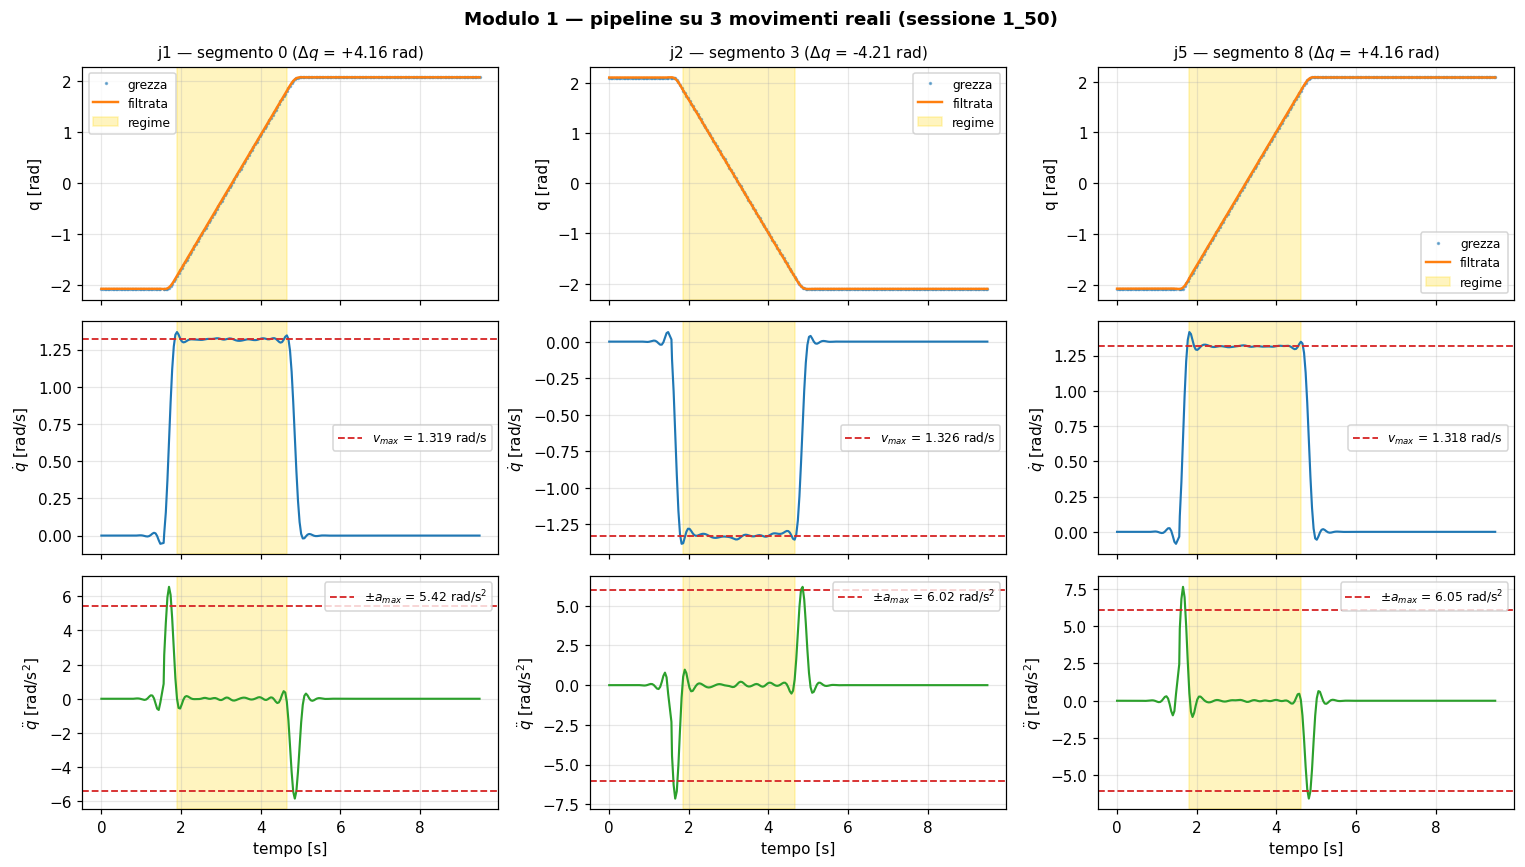

In [9]:
def plot_movimento(res, ax_col):
    """Posizione (grezza + filtrata), velocita' e accelerazione di un movimento."""
    tt = res.time
    ss = res.steady_state_window

    ax_col[0].plot(tt, res.position_raw, ".", ms=2.5, alpha=0.5, label="grezza")
    ax_col[0].plot(tt, res.position_filtered, lw=1.6, color="C1", label="filtrata")
    ax_col[0].set_ylabel("q [rad]")
    ax_col[0].set_title(
        f"{res.joint_name} — segmento {res.segment_index} "
        f"($\\Delta q$ = {res.delta_q:+.2f} rad)", fontsize=10)

    ax_col[1].plot(tt, res.velocity, lw=1.4, color="C0")
    if res.vmax_est:
        ax_col[1].axhline(np.sign(res.delta_q) * res.vmax_est, color="C3", ls="--", lw=1.2,
                          label=f"$v_{{max}}$ = {res.vmax_est:.3f} rad/s")
    ax_col[1].set_ylabel(r"$\dot q$ [rad/s]")

    ax_col[2].plot(tt, res.acceleration, lw=1.4, color="C2")
    if res.amax_est:
        for sgn in (1, -1):
            ax_col[2].axhline(sgn * res.amax_est, color="C3", ls="--", lw=1.2)
        ax_col[2].plot([], [], color="C3", ls="--", lw=1.2,
                       label=f"$\\pm a_{{max}}$ = {res.amax_est:.2f} rad/s$^2$")
    ax_col[2].set(ylabel=r"$\ddot q$ [rad/s$^2$]", xlabel="tempo [s]")

    # Finestra di regime evidenziata su tutti e tre i pannelli
    for ax in ax_col:
        if ss is not None:
            ax.axvspan(tt[ss[0]], tt[ss[1] - 1], color="gold", alpha=0.25,
                       label="regime" if ax is ax_col[0] else None)
        ax.legend(fontsize=8, loc="best")


fig, axes = plt.subplots(3, 3, figsize=(14, 8), sharex="col")
for j, res in enumerate(risultati):
    plot_movimento(res, axes[:, j])
fig.suptitle("Modulo 1 — pipeline su 3 movimenti reali (sessione 1_50)", fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES / "01_pipeline_3_movimenti.png", dpi=150, bbox_inches="tight")
plt.show()

Lettura dei grafici:

* la **posizione filtrata** segue la grezza senza sfasamento, merito di `filtfilt`;
* la **velocità** mostra un plateau netto: il profilo è chiaramente trapezoidale;
* l'**accelerazione** è il segnale più delicato — le rampe durano `vmax/amax ≈ 0.22 s`,
  circa 5 campioni, e il filtro le smussa: `amax` va letta come **limite inferiore**;
* la **fascia gialla** è la finestra di regime, e cade dentro il plateau come deve.

In [10]:
for r in risultati:
    print(f"--- {r.joint_name} (segmento {r.segment_index}) ---")
    if r.warnings:
        for w in r.warnings:
            print("   !", w)
    else:
        print("   nessun warning")

--- j1 (segmento 0) ---
   ! campionamento non uniforme: CV(dt) = 8.18% > 1.00%
   ! rampa di 243 ms piu' breve dello smussamento del filtro (333 ms a 3 Hz): amax e' SOTTOSTIMATA, va usata come limite inferiore
--- j2 (segmento 3) ---
   ! campionamento non uniforme: CV(dt) = 8.03% > 1.00%
   ! rampa di 220 ms piu' breve dello smussamento del filtro (333 ms a 3 Hz): amax e' SOTTOSTIMATA, va usata come limite inferiore
--- j5 (segmento 8) ---
   ! campionamento non uniforme: CV(dt) = 7.97% > 1.00%
   ! rampa di 218 ms piu' breve dello smussamento del filtro (333 ms a 3 Hz): amax e' SOTTOSTIMATA, va usata come limite inferiore


## 4. L'intero dataset

`analyze_dataset` percorre tutte le sessioni e produce la tabella che il Modulo 3 userà
come punto di partenza, salvata in `data/processed/preprocessing_params.csv`.

In [11]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    tutti, tabella = analyze_dataset(DATA_RAW, config=cfg, verbose=True)

percorso = save_results(tabella, DATA_PROCESSED / "preprocessing_params.csv")
print(f"\nSalvato: {percorso.relative_to(ROOT)}  ->  {tabella.shape[0]} movimenti")
tabella.head()
None

   1_100: 12 movimenti analizzati
    1_50: 12 movimenti analizzati
    1_75: 12 movimenti analizzati
      25: 12 movimenti analizzati
   2_100: 12 movimenti analizzati
    2_50: 12 movimenti analizzati
    2_75: 12 movimenti analizzati
   3_100: 12 movimenti analizzati
    3_50: 12 movimenti analizzati
    3_75: 12 movimenti analizzati
   4_100: 12 movimenti analizzati

Salvato: data/processed/preprocessing_params.csv  ->  132 movimenti


In [12]:
riassunto = (tabella
             .groupby("commanded_velocity")
             .agg(n=("vmax_est", "size"),
                  vmax_media=("vmax_est", "mean"),
                  vmax_std=("vmax_est", "std"),
                  amax_media=("amax_est", "mean"),
                  amax_std=("amax_est", "std"),
                  regime_s=("steady_state_duration", "mean"))
             .round(4))
riassunto.to_csv(TABLES / "01_riassunto_per_velocita.csv")
riassunto

,n,vmax_media,vmax_std,amax_media,amax_std,regime_s
commanded_velocity,,,,,,
25.0,12,0.6584,0.0029,3.1451,0.1807,5.9410
50.0,36,1.3176,0.0066,5.8073,0.2508,2.8382
75.0,36,1.9770,0.0107,7.3207,0.3164,1.7447
100.0,48,2.6386,0.0148,7.8445,0.2342,1.1501


Il risultato principale di questa fase: **`vmax` cresce linearmente con la velocità
comandata**, con dispersione sotto l'1% su 6 giunti, 2 direzioni e più ripetizioni. La
relazione comando → velocità fisica è ben identificabile.

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

for nome, gruppo in tabella.groupby("joint_name"):
    axes[0].plot(gruppo["commanded_velocity"], gruppo["vmax_est"], "o", ms=5,
                 alpha=0.7, label=nome)
vel = riassunto.index.to_numpy(dtype=float)
coef = np.polyfit(tabella["commanded_velocity"], tabella["vmax_est"], 1)
axes[0].plot(vel, np.polyval(coef, vel), "k--", lw=1.2,
             label=f"fit: {coef[0]:.4f}·vel {coef[1]:+.4f}")
axes[0].set(xlabel="velocita' comandata [1-100]", ylabel=r"$v_{max}$ [rad/s]",
            title="Velocita' di crociera identificata")
axes[0].legend(fontsize=8, ncol=2)

for nome, gruppo in tabella.groupby("joint_name"):
    axes[1].plot(gruppo["commanded_velocity"], gruppo["amax_est"], "s", ms=5,
                 alpha=0.7, label=nome)
axes[1].set(xlabel="velocita' comandata [1-100]", ylabel=r"$a_{max}$ [rad/s$^2$]",
            title="Accelerazione identificata (limite inferiore)")

fig.tight_layout()
fig.savefig(FIGURES / "01_vmax_amax_vs_comando.png", dpi=150, bbox_inches="tight")
plt.close(fig)

print(f"Relazione lineare: vmax = {coef[0]:.5f} * velocita_comandata {coef[1]:+.5f} rad/s")

Relazione lineare: vmax = 0.02641 * velocita_comandata -0.00279 rad/s


In [14]:
print("Tipi di profilo rilevati:", tabella["profile_type"].value_counts().to_dict())
print("Movimenti affidabili   :", tabella["reliable"].value_counts().to_dict())
print("amax affidabile        :", tabella["amax_reliable"].value_counts().to_dict())

Tipi di profilo rilevati: {'trapezoidal': 132}
Movimenti affidabili   : {True: 132}
amax affidabile        : {False: 102, True: 30}


## 5. Cosa portare in tesi

* Il dataset: **132 movimenti** (11 sessioni × 12), 6 giunti × 2 direzioni, a 4 velocità
  comandate. Campionamento reale a 25 Hz, passo mediano 40.1 ms.
* **Il Δt irregolare non è jitter** ma sono le pause fra un movimento e l'altro: è la
  premessa che giustifica la segmentazione sui buchi temporali.
* La scelta della frequenza di taglio a 3 Hz, motivata dal contenuto spettrale del segnale
  e dall'amplificazione del rumore di quantizzazione come `cutoff²`.
* **`vmax` è proporzionale al comando**, con dispersione sotto l'1% su giunti, direzioni e
  ripetizioni.
* **`amax` è una sottostima** e la pipeline lo segnala da sola: il filtro smussa la rampa
  prima che il plateau sia raggiunto. È il motivo per cui serve il fitting.
* Tutti i movimenti sono **trapezoidali**: l'escursione di ~4.2 rad è ben oltre la soglia
  `vmax²/amax`, quindi il ramo triangolare non è messo alla prova da questi dati.